# Advanced Exploratory Data Analysis (EDA) of PTB-XL Dataset

This notebook is specific for visualizations of the dataset. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import ast
import os

# Set high-end visual aesthetics
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({'font.size': 12})

## 1. Load Metadata
First, we load the previously cleaned metadata `results/ptbxl_metadata_with_superclasses.csv` that contains labels, and extract necessary representations.

In [ ]:
DATA_DIR = '../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'
META_PATH = '../results/ptbxl_metadata_with_superclasses.csv'

df = pd.read_csv(META_PATH)

# scp_codes was saved in pevious notebook as string : convert back to dict
df['scp_codes'] = df['scp_codes'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else {})

print(f"Total clinical records: {len(df)}")
df.head(3)

Total clinical records: 21799


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,strat_fold,filename_lr,filename_hr,diagnostic_superclass,num_diagnostic_superclasses,CD,HYP,MI,NORM,STTC
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,3,records100/00000/00001_lr,records500/00000/00001_hr,['NORM'],1,0,0,0,1,0
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,2,records100/00000/00002_lr,records500/00000/00002_hr,['NORM'],1,0,0,0,1,0
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,5,records100/00000/00003_lr,records500/00000/00003_hr,['NORM'],1,0,0,0,1,0


## 2. Demographics Distribution
Analyzing the basic demographics such as the age and sex of the patients in the dataset.

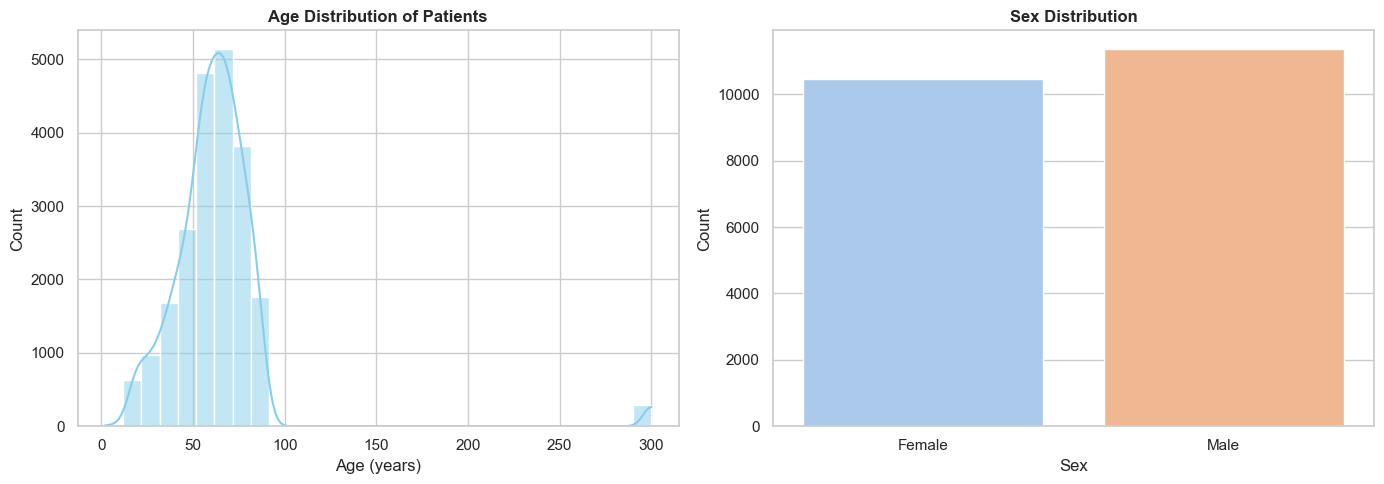

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age Distribution
sns.histplot(data=df, x='age', bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Age Distribution of Patients', fontweight='bold')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Count')

# Sex Distribution
# 0 denotes Male & 1 denotes Female
sex_mapping = {0: 'Male', 1: 'Female'}
df['sex_label'] = df['sex'].map(sex_mapping).fillna('Unknown')
sns.countplot(data=df, x='sex_label', hue='sex_label', legend=False, palette='pastel')
axes[1].set_title('Sex Distribution', fontweight='bold')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [9]:
df[df['age'] > 120]

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,filename_lr,filename_hr,diagnostic_superclass,num_diagnostic_superclasses,CD,HYP,MI,NORM,STTC,sex_label
107,108,11810.0,300.0,1,NaN,57.0,0.0,0.0,CS-12 E,1985-12-20 11:54:45,...,records100/00000/00108_lr,records500/00000/00108_hr,['NORM'],1,0,0,0,1,0,Female
247,255,4867.0,300.0,1,163.0,58.0,10.0,1.0,AT-6 C 5.0,1986-09-05 14:25:22,...,records100/00000/00255_lr,records500/00000/00255_hr,['CD'],1,1,0,0,0,0,Female
248,256,565.0,300.0,1,168.0,61.0,8.0,1.0,AT-6 C 5.5,1986-09-05 14:57:27,...,records100/00000/00256_lr,records500/00000/00256_hr,['CD'],1,1,0,0,0,0,Female
271,279,437.0,300.0,0,175.0,NaN,6.0,1.0,AT-6 C 5.5,1986-09-09 15:59:30,...,records100/00000/00279_lr,records500/00000/00279_hr,['CD'],1,1,0,0,0,0,Male
274,282,437.0,300.0,0,175.0,NaN,3.0,1.0,AT-6 C 5.5,1986-09-10 11:31:08,...,records100/00000/00282_lr,records500/00000/00282_hr,"['CD', 'HYP', 'MI', 'STTC']",4,1,1,1,0,1,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20826,20865,14863.0,300.0,1,NaN,NaN,1.0,2.0,AT-60 3,1999-11-25 07:33:25,...,records100/20000/20865_lr,records500/20000/20865_hr,"['CD', 'MI']",2,1,0,1,0,0,Female
20839,20878,11174.0,300.0,1,NaN,NaN,1.0,2.0,AT-60 3,1999-11-28 13:49:12,...,records100/20000/20878_lr,records500/20000/20878_hr,"['HYP', 'STTC']",2,0,1,0,0,1,Female
21082,21121,16658.0,300.0,1,NaN,NaN,1.0,2.0,CS-12,2000-06-20 11:05:26,...,records100/21000/21121_lr,records500/21000/21121_hr,"['MI', 'STTC']",2,0,0,1,0,1,Female
21101,21140,18376.0,300.0,1,NaN,NaN,1.0,2.0,CS-12,2000-07-05 18:51:58,...,records100/21000/21140_lr,records500/21000/21140_hr,"['CD', 'MI']",2,1,0,1,0,0,Female


The reason why we have the 300.0 for age is purely for anonimity purposes, it is explained in the physionet dataset website. 

## 3. Diagnostic Superclass Distibution & Class Imbalance
Main superclasses 
1. **NORM**: Normal ECG
2. **MI**: Myocardial Infarction
3. **STTC**: ST/T Change
4. **CD**: Conduction Disturbance
5. **HYP**: Hypertrophy

C:\Users\Sherif\AppData\Local\Temp\ipykernel_24900\1178311229.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')


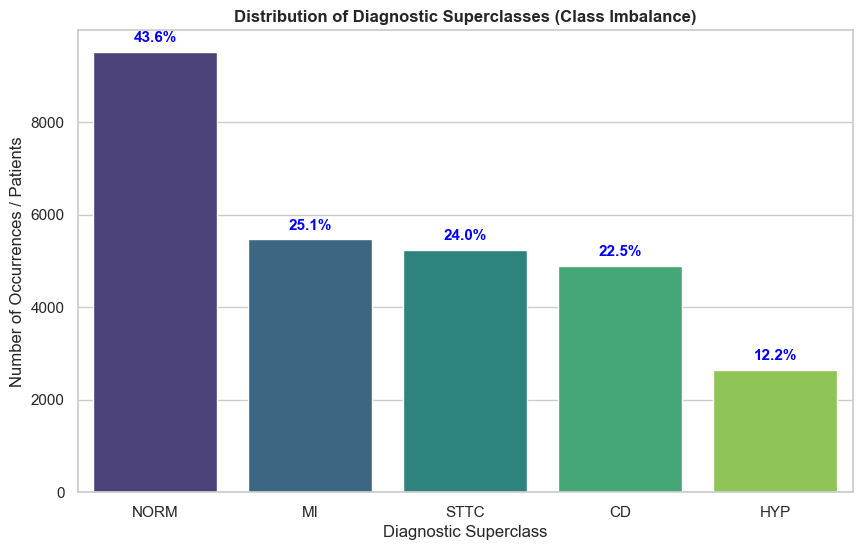

In [5]:
superclasses = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
class_counts = df[superclasses].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Distribution of Diagnostic Superclasses (Class Imbalance)', fontweight='bold')
plt.xlabel('Diagnostic Superclass')
plt.ylabel('Number of Occurrences / Patients')

# Add percentage labels for better clarity
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, color='blue', xytext=(0, 5),
                textcoords='offset points', fontweight='bold')

plt.show()

## 4. ECG Signal (waveform) Visualization
Plotting a comprehensive visual summary of the 12 standard leads across a specific sample.

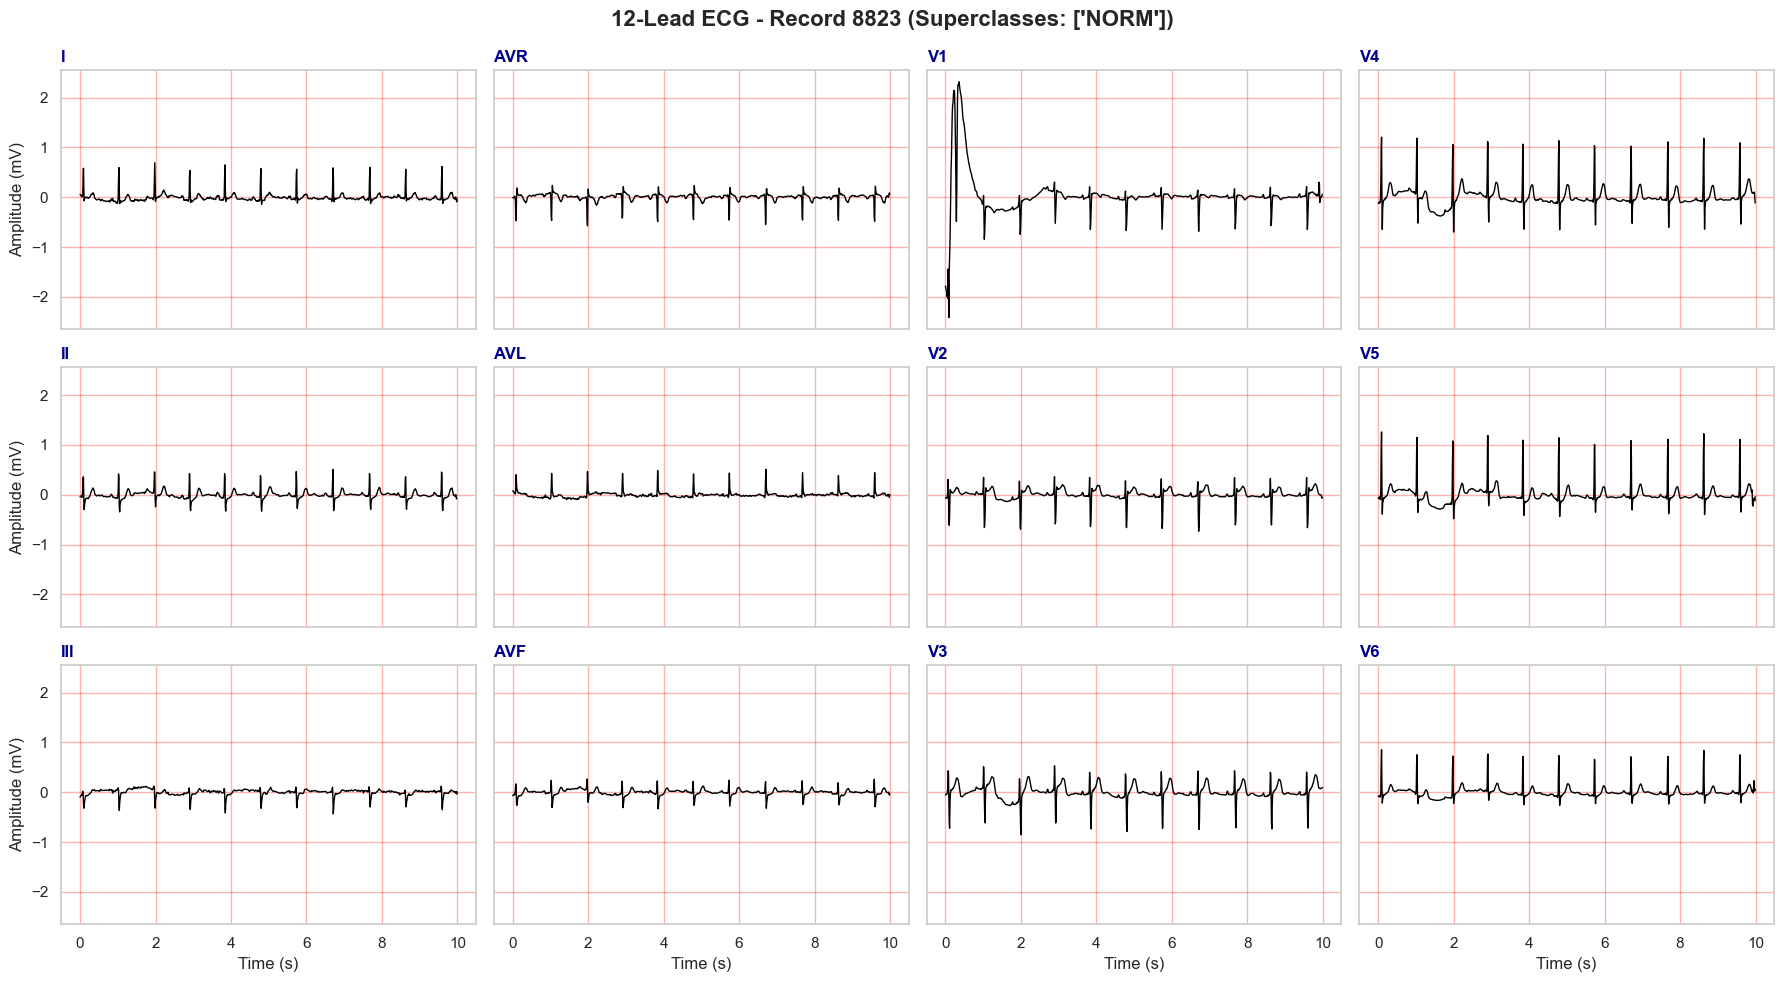

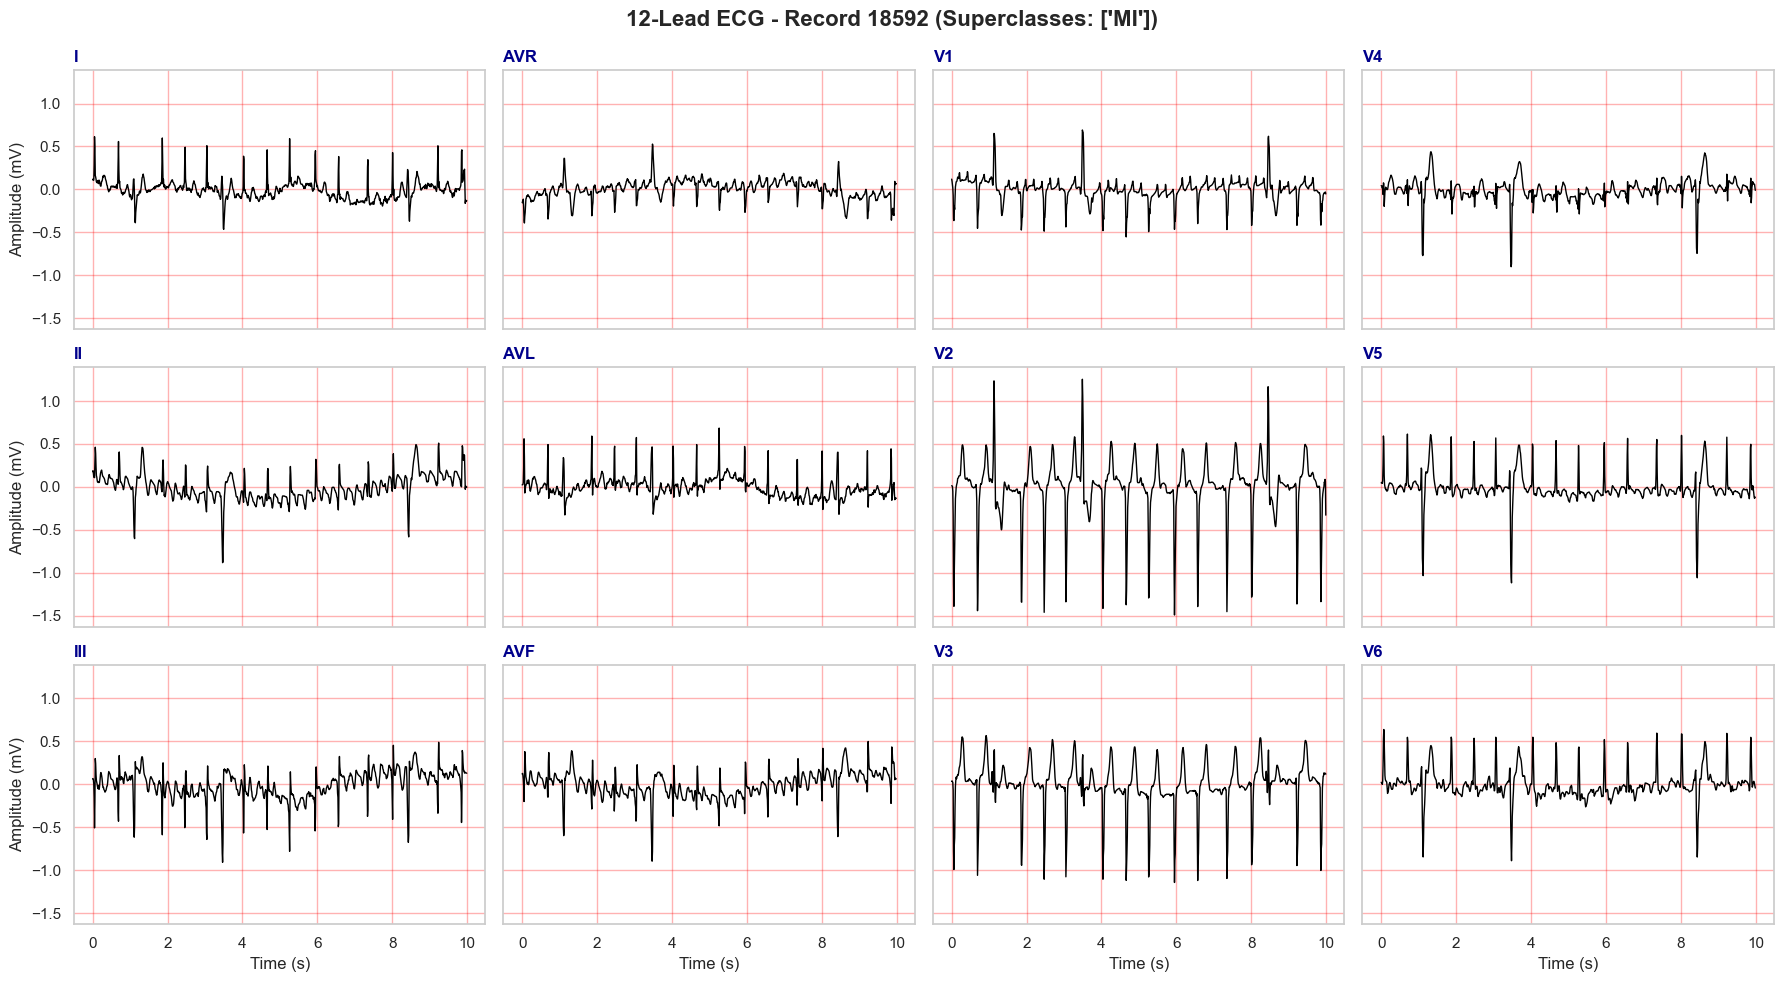

In [7]:
def plot_12_lead_ecg(ecg_id, df, data_dir, freq='100'):
    """Plots a standard 12-lead ECG layout. 
    Grid is superimposed as red."""
    row = df[df['ecg_id'] == ecg_id].iloc[0]
    filename = row['filename_lr'] if freq == '100' else row['filename_hr']
    path = os.path.join(data_dir, filename)
    
    try:
        signal, meta = wfdb.rdsamp(path)
    except FileNotFoundError:
        print(f"File {path} not found. Please ensure dataset is correctly extracted.")
        return
        
    leads = meta['sig_name']
    
    # 4 columns x 3 rows is standard presentation for 12 leads
    fig, axes = plt.subplots(3, 4, figsize=(18, 10), sharex=True, sharey=True)
    fig.suptitle(f"12-Lead ECG - Record {ecg_id} (Superclasses: {row['diagnostic_superclass']})", 
                 fontsize=16, fontweight='bold', y=0.98)
    
    layout = [
        ['I', 'AVR', 'V1', 'V4'],
        ['II', 'AVL', 'V2', 'V5'],
        ['III', 'AVF', 'V3', 'V6']
    ]
    
    time = np.arange(signal.shape[0]) / meta['fs']
    
    for i in range(3):
        for j in range(4):
            lead_name = layout[i][j]
            if lead_name in leads:
                lead_idx = leads.index(lead_name)
                # Add grid to imitate standardized ECG paper
                axes[i, j].grid(True, which='both', color='red', alpha=0.3)
                axes[i, j].plot(time, signal[:, lead_idx], color='black', linewidth=1)
                # Set clear titles, e.g V1, V2 etc.
                axes[i, j].set_title(lead_name, loc='left', color='darkblue', fontweight='bold', fontsize=12)
                
                if i == 2:
                    axes[i, j].set_xlabel("Time (s)")
                if j == 0:
                    axes[i, j].set_ylabel("Amplitude (mV)")
                    
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()

#clean 'Healthy' sample
norm_sample = df[df['NORM'] == 1]['ecg_id'].sample(1, random_state=42).iloc[0]
plot_12_lead_ecg(norm_sample, df, DATA_DIR, freq='100')

#'Infarction' sample to look for noticeable pattern deviations
mi_sample = df[df['MI'] == 1]['ecg_id'].sample(1, random_state=42).iloc[0]
plot_12_lead_ecg(mi_sample, df, DATA_DIR, freq='100')

In [11]:
df.columns

Index(['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse',
       'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr',
       'diagnostic_superclass', 'num_diagnostic_superclasses', 'CD', 'HYP',
       'MI', 'NORM', 'STTC', 'sex_label'],
      dtype='str')

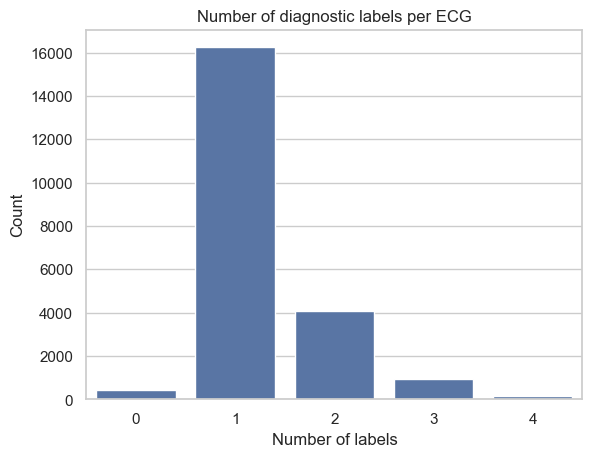

In [12]:
sns.countplot(x=df['num_diagnostic_superclasses'])
plt.title("Number of diagnostic labels per ECG")
plt.xlabel("Number of labels")
plt.ylabel("Count")
plt.show()

So in one ECG we can have un to 4 cooccuring pathologies. 

what we can do is take a look at a co occurence matrix

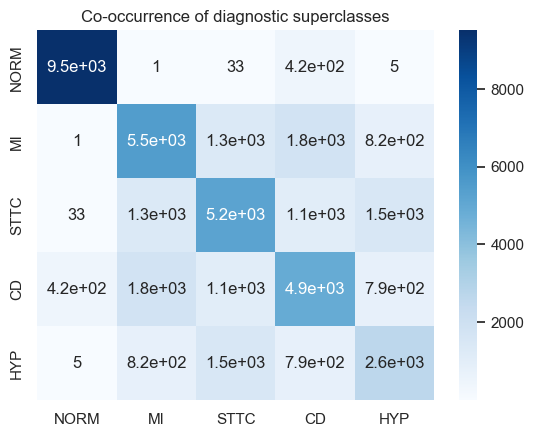

In [13]:
labels = ['NORM','MI','STTC','CD','HYP']

cooc = df[labels].T @ df[labels]

sns.heatmap(cooc, annot=True, cmap='Blues')
plt.title("Co-occurrence of diagnostic superclasses")
plt.show()

I should normalize the heatmap to have proportios instead 

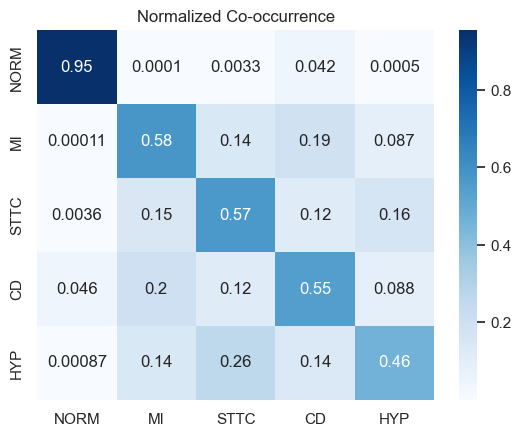

In [14]:
cooc_norm = cooc / cooc.sum(axis=1).values[:, None]

sns.heatmap(cooc_norm, annot=True, cmap='Blues')
plt.title("Normalized Co-occurrence")
plt.show()

## Interpretation of Class Distribution and superclass Relationships

### Dataset structure and class imbalance

As it was explained in the dataset’s website (https://physionet.org/content/ptb-xl/1.0.3/), PTB-XL is a large-scale clinical ECG dataset where each recording can be annotated with multiple diagnostic statements.

From the class distribution, a clear imbalance is observed. The NORM class dominates the dataset, while MI, STTC, and CD remain well represented but less frequent, and HYP appears significantly underrepresented. This imbalance could mean that learning will be biased toward dominant class.


### Multi-label nature of the problem

Again as it was described in the original PTB-XL paper, the dataset is explicitly designed as a multi-label classification problem, where each ECG can have several simultaneous diagnostic labels. 

This is confirmed by the distribution of the number of labels per ECG, showing that many recordings contain more than one pathology. This reflects real clinical conditions and increases the complexity of the task compared to standard single-label classification.


### Co-occurrence patterns and clinical consistency

The co-occurrence matrix reveals structured relationships between pathologies.

MI frequently appears together with STTC and CD, which is consistent with the physiological effects of ischemic damage on both repolarization and conduction. STTC shows strong overlap with multiple classes, suggesting that it represents a non-specific but common abnormality across different cardiac conditions. Similarly, HYP co-occurs with STTC and CD, indicating that structural changes in the heart affect both waveform morphology and electrical conduction.

Such patterns are consistent with observations reported in recent studies on PTB-XL, where strong co-occurrence between MI, STTC, CD, and HYP has been identified, highlighting the overlapping nature of cardiac conditions and the complexity of multi-label ECG classification (https://arxiv.org/html/2504.16101v1).


### Implications for modeling

I want to approach this task as a structured multi-label problem, where dependencies between labels are important for accurate prediction.


### Preliminary selection of target pathologies

Based on both class distribution and co-occurrence structure, MI, STTC, and CD appear to be the most suitable candidates for classification. They are sufficiently represented and balanced between them and exhibit meaningful relationships, making them both clinically relevant and non-trivial to model.